# Effluent ammonium and nitrate: compare preparation strategies and predict one hour ahead

Read the shared minute-level `data_filled.csv` and Boolean mask exported by notebook 01 or 02. Recover observations by masking filled cells. Do not read old 20-minute exports or fetch extra SQL history. Source coverage is April 14–23, 2026. Seven-day final training covers April 14–20 and ends before April 21; test origins cover April 21–23.

Compare 24 preparations: raw / unlimited forward fill / five-minute age-limited inputs; 1/5/10/20-minute input summaries; current features / compact 1/3/6-hour lags; a fixed seven-day final training window. Select preparation and its screening algorithm (mean, Ridge or Extra Trees) by mean RMSE on three purged April 18–20 validation days. Additional fixed XGBoost and Random Forest models are comparison references. No strategy is selected on test scores.

All strategies use identical **20-minute forecast origins** and the same **observed exact-minute target one hour later**. Input aggregation never changes the forecasting objective. Missing inputs use training-only median imputation with indicators; unobserved/constant sensors are excluded per fold. Measurement age and observed support accompany values. A 20-minute origin schedule differs from the earlier minute-origin experiments, so compare strategies using this run's common labels.

Long repeated signals are audited and evaluated in a separate sensitivity report; they are not automatically deleted. Earlier source fills cannot be reconstructed if the source mask marked them observed. Validation folds expand over four, five and six days inside the training week; the final fit uses all seven days. Fourteen- and twenty-eight-day histories remain unavailable. These previously inspected test dates remain exploratory.

The primary algorithm comparison is **XGBoost, LSTM and Ridge Regression**, plus persistence. All three use identical 12-step historical sequences sampled every 20 minutes; tree/linear inputs are flattened. LSTM epochs are selected on a purged chronological training-only tail, then the network is refitted on all eligible training sequences. Initial sequence warmup reduces the effective training-origin count; calendar coverage remains seven days.

Forecast, error-comparison and LSTM-loss charts are saved under each target’s `comparison_xgb_lstm_ridge/` directory. SQL is the selected source; notebook 02 keeps its exports separate.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "config/sensors.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch from the repository root or notebooks directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))
from config.eff_nh3_n import CONFIG as A1_CONFIG
from config.eff_no3_n import CONFIG as A2_CONFIG
MODEL_CONFIGS = {cfg["name"]: dict(cfg) for cfg in (A1_CONFIG,A2_CONFIG)}
from importlib import reload
import src.preparation_experiments as preparation_experiments
reload(preparation_experiments)


<module 'src.preparation_experiments' from '/home/bryan1010/projects/ao-mbr-data-pipeline/src/preparation_experiments.py'>

## Run controlled preparation comparisons and forecasts

This cell performs validation screening, then fits the selected preparation on pre-test data. It saves every preparation's held-out forecasts for review, the validation ranking, all-algorithm comparisons under the selected preparation, observation-quality audits and reproducibility metadata. The shared source exports stay unchanged. Re-running replaces only this notebook's strategy artifacts.


In [2]:
results, OUTPUT_DIR = preparation_experiments.run_group(MODEL_CONFIGS, PROJECT_ROOT, "effluent")


Screening eff_nh3_n: 24 preparations, 3 models, 3 pre-test folds
Comparing XGBoost, LSTM and Ridge: eff_nh3_n
Selected eff_nh3_n: {'policy': 'raw', 'input_minutes': 5, 'representation': 'lags', 'history': '7day', 'algorithm': 'ridge', 'mean_validation_rmse': 0.01093342938727439, 'target': 'Eff_NH4_N', 'active_sensors': ['A1_Qin', 'A2_Qin', 'A1_COD_in', 'A2_COD_in', 'A1_O_PH', 'A1_O_ORP', 'A1_O_DO', 'A1_O_MLSS', 'A2_O_PH', 'A2_O_ORP', 'A2_O_DO', 'Q_A1_air', 'Q_A2_air', 'Eff_NH4_N'], 'excluded_sensors': ['A1_NH3_N', 'A2_NH3_N', 'A2_O_MLSS'], 'train_rows': 501, 'test_origins': 213, 'training_start': '2026-04-14 00:00:00', 'training_end_inclusive': '2026-04-20 23:59:00', 'last_allowed_target_time': '2026-04-23 23:59:00', 'validation_history': 'expanding within April 14–20; four/five/six days depending on fold', 'last_train_label': '2026-04-21 00:00:00', 'test_start': '2026-04-21 00:00:00', 'selection_basis': 'mean April 18–20 validation RMSE; no test selection', 'label': 'observed exact mi

## Review selected strategies and measured-label accuracy

`all_observed` uses labels indicated as observed by the source mask. `exclude_suspected_stale` is a sensitivity calculation that omits labels after at least 60 consecutive identical observed minutes. Constant measured targets have undefined R². Neither sensitivity nor test comparison changes validation selection. Methanol errors use m³/hour and airflow errors use m³/min; these are forecasts of recorded flows, not operating prescriptions.


In [3]:
for name, result in results.items():
    print(name, "validation-selected preparation:", result["selection"])
    display(result["ranking"].head(10))
    display(result["metrics"])
    display(result["forecasts"].head())

    print("XGBoost / LSTM / Ridge comparison (identical sequence inputs):")
    display(result["algorithm_comparison"]["metrics"])
    display(result["algorithm_comparison"]["forecasts"].head())


eff_nh3_n validation-selected preparation: {'policy': 'raw', 'input_minutes': 5, 'representation': 'lags', 'history': '7day', 'algorithm': 'ridge', 'mean_validation_rmse': 0.01093342938727439, 'target': 'Eff_NH4_N', 'active_sensors': ['A1_Qin', 'A2_Qin', 'A1_COD_in', 'A2_COD_in', 'A1_O_PH', 'A1_O_ORP', 'A1_O_DO', 'A1_O_MLSS', 'A2_O_PH', 'A2_O_ORP', 'A2_O_DO', 'Q_A1_air', 'Q_A2_air', 'Eff_NH4_N'], 'excluded_sensors': ['A1_NH3_N', 'A2_NH3_N', 'A2_O_MLSS'], 'train_rows': 501, 'test_origins': 213, 'training_start': '2026-04-14 00:00:00', 'training_end_inclusive': '2026-04-20 23:59:00', 'last_allowed_target_time': '2026-04-23 23:59:00', 'validation_history': 'expanding within April 14–20; four/five/six days depending on fold', 'last_train_label': '2026-04-21 00:00:00', 'test_start': '2026-04-21 00:00:00', 'selection_basis': 'mean April 18–20 validation RMSE; no test selection', 'label': 'observed exact minute value at forecast origin plus one hour', 'forecast_origin_frequency': '20min, iden

,policy,input_minutes,representation,history,algorithm,mean_validation_rmse
0,raw,5,lags,7day,ridge,0.010933
1,ffill,5,lags,7day,ridge,0.010979
2,age5,5,lags,7day,ridge,0.010979
3,raw,5,current,7day,extra_trees,0.011115
4,ffill,5,current,7day,ridge,0.011171
5,age5,5,current,7day,ridge,0.011171
6,age5,1,lags,7day,ridge,0.011192
7,ffill,5,current,7day,extra_trees,0.011205
8,age5,5,current,7day,extra_trees,0.011205
9,raw,10,current,7day,extra_trees,0.011209


,target,algorithm,scope,n,mae,rmse,r2
0,Eff_NH4_N,mean,all_observed,211,0.009813,0.011731,-0.115139
1,Eff_NH4_N,mean,exclude_suspected_stale,181,0.009433,0.011668,-0.043723
2,Eff_NH4_N,ridge,all_observed,211,0.057483,0.168340,-228.619461
3,Eff_NH4_N,ridge,exclude_suspected_stale,181,0.009716,0.012079,-0.118463
4,Eff_NH4_N,extra_trees,all_observed,211,0.010055,0.012077,-0.181841
5,Eff_NH4_N,extra_trees,exclude_suspected_stale,181,0.009535,0.011881,-0.082101
6,Eff_NH4_N,random_forest,all_observed,211,0.009758,0.011660,-0.101693
7,Eff_NH4_N,random_forest,exclude_suspected_stale,181,0.009458,0.011675,-0.044809
8,Eff_NH4_N,xgboost,all_observed,211,0.009908,0.011823,-0.132531
9,Eff_NH4_N,xgboost,exclude_suspected_stale,181,0.009611,0.011839,-0.074525


,target_time,actual,actual_observed,suspected_stale_target,target_within_source_window,mean,ridge,extra_trees,random_forest,xgboost,persistence
forecast_origin,,,,,,,,,,,
2026-04-21 00:00:00,2026-04-21 01:00:00,0.1900,True,False,True,0.195496,0.192184,0.196282,0.195785,0.195151,0.201800
2026-04-21 00:20:00,2026-04-21 01:20:00,0.2050,True,False,True,0.195496,0.198363,0.196354,0.196463,0.198576,0.161875
2026-04-21 00:40:00,2026-04-21 01:40:00,0.2150,True,False,True,0.195496,0.197208,0.196510,0.196059,0.195586,0.195200
2026-04-21 01:00:00,2026-04-21 02:00:00,0.2232,True,False,True,0.195496,0.199986,0.196175,0.197439,0.198835,0.190000
2026-04-21 01:20:00,2026-04-21 02:20:00,0.2076,True,False,True,0.195496,0.188522,0.190518,0.196024,0.190985,0.205000


XGBoost / LSTM / Ridge comparison (identical sequence inputs):


...

,target,algorithm,scope,n,mae,rmse,r2
0,Eff_NO3_N,mean,all_observed,211,0.0,0.0,NaN
1,Eff_NO3_N,mean,exclude_suspected_stale,43,0.0,0.0,NaN
2,Eff_NO3_N,ridge,all_observed,211,0.0,0.0,NaN
3,Eff_NO3_N,ridge,exclude_suspected_stale,43,0.0,0.0,NaN
4,Eff_NO3_N,extra_trees,all_observed,211,0.0,0.0,NaN
5,Eff_NO3_N,extra_trees,exclude_suspected_stale,43,0.0,0.0,NaN
6,Eff_NO3_N,random_forest,all_observed,211,0.0,0.0,NaN
7,Eff_NO3_N,random_forest,exclude_suspected_stale,43,0.0,0.0,NaN
8,Eff_NO3_N,xgboost,all_observed,211,0.0,0.0,NaN
9,Eff_NO3_N,xgboost,exclude_suspected_stale,43,0.0,0.0,NaN


,target_time,actual,actual_observed,suspected_stale_target,target_within_source_window,mean,ridge,extra_trees,random_forest,xgboost,persistence
forecast_origin,,,,,,,,,,,
2026-04-21 00:00:00,2026-04-21 01:00:00,5.0,True,True,True,5.0,5.0,5.0,5.0,5.0,5.0
2026-04-21 00:20:00,2026-04-21 01:20:00,5.0,True,True,True,5.0,5.0,5.0,5.0,5.0,5.0
2026-04-21 00:40:00,2026-04-21 01:40:00,5.0,True,True,True,5.0,5.0,5.0,5.0,5.0,5.0
2026-04-21 01:00:00,2026-04-21 02:00:00,5.0,True,True,True,5.0,5.0,5.0,5.0,5.0,5.0
2026-04-21 01:20:00,2026-04-21 02:20:00,5.0,True,False,True,5.0,5.0,5.0,5.0,5.0,5.0


XGBoost / LSTM / Ridge comparison (identical sequence inputs):


,target,algorithm,scope,n,mae,rmse,r2
0,Eff_NO3_N,xgboost,all_observed,211,0.000000,0.000000,NaN
1,Eff_NO3_N,xgboost,exclude_suspected_stale,43,0.000000,0.000000,NaN
2,Eff_NO3_N,lstm,all_observed,211,0.054262,0.125797,NaN
3,Eff_NO3_N,lstm,exclude_suspected_stale,43,0.011078,0.017793,NaN
4,Eff_NO3_N,ridge,all_observed,211,0.000000,0.000000,NaN
5,Eff_NO3_N,ridge,exclude_suspected_stale,43,0.000000,0.000000,NaN
6,Eff_NO3_N,persistence,all_observed,211,0.000000,0.000000,NaN
7,Eff_NO3_N,persistence,exclude_suspected_stale,43,0.000000,0.000000,NaN


,target_time,actual,actual_observed,suspected_stale_target,lstm,xgboost,ridge,persistence
forecast_origin,,,,,,,,
2026-04-21 00:00:00,2026-04-21 01:00:00,5.0,True,True,4.995960,5.0,5.0,5.0
2026-04-21 00:20:00,2026-04-21 01:20:00,5.0,True,True,4.999932,5.0,5.0,5.0
2026-04-21 00:40:00,2026-04-21 01:40:00,5.0,True,True,4.997258,5.0,5.0,5.0
2026-04-21 01:00:00,2026-04-21 02:00:00,5.0,True,True,4.993911,5.0,5.0,5.0
2026-04-21 01:20:00,2026-04-21 02:20:00,5.0,True,False,4.999026,5.0,5.0,5.0


## Visualize held-out forecasts and training context

Blue shows the validation-selected model, orange persistence and black observed future targets. Red markers flag long repeated target readings for source review. All forecast origins and future target timestamps are restricted to April 23 or earlier. Each CSV preserves the forecast-origin and future target timestamps.


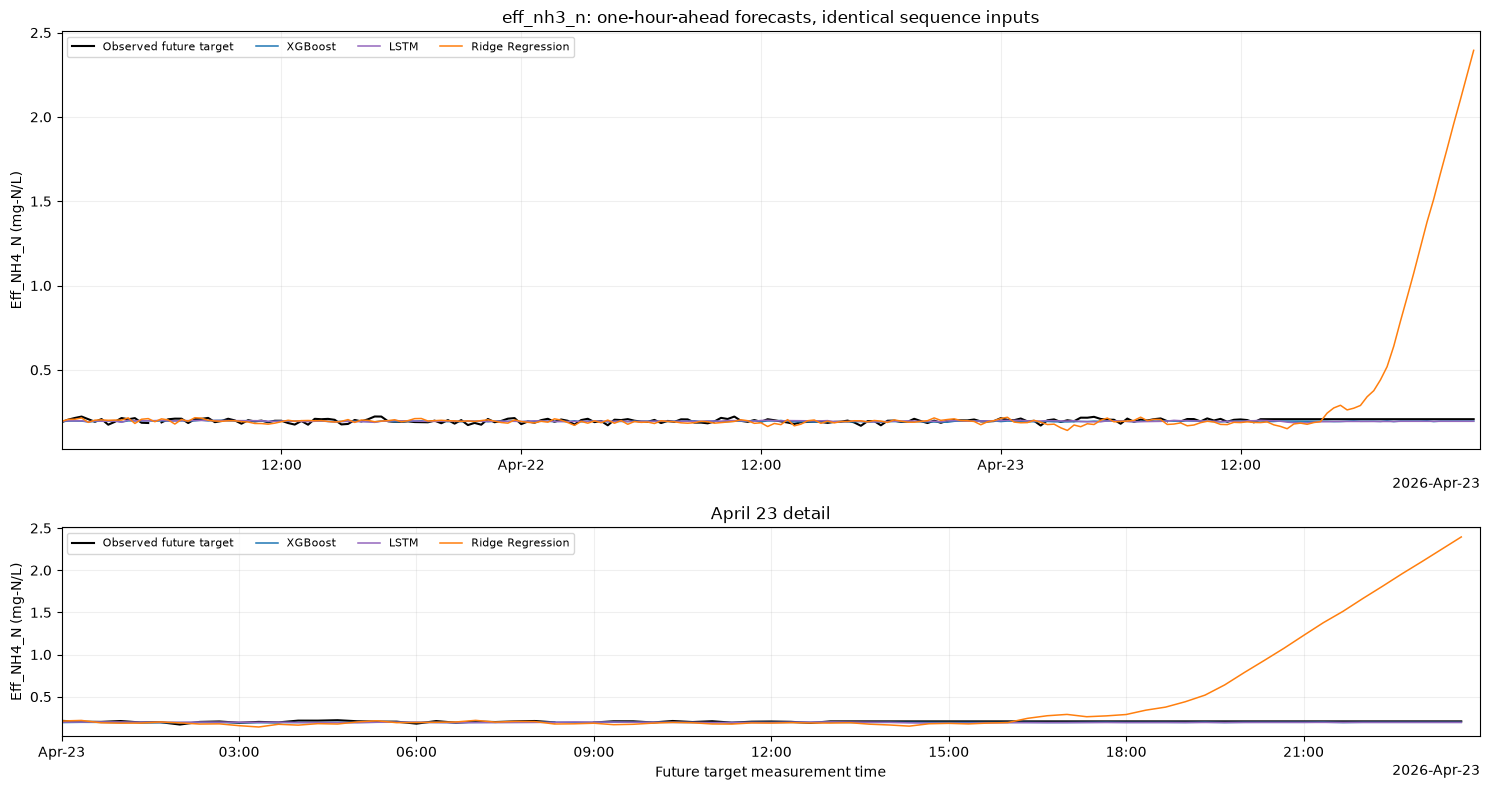

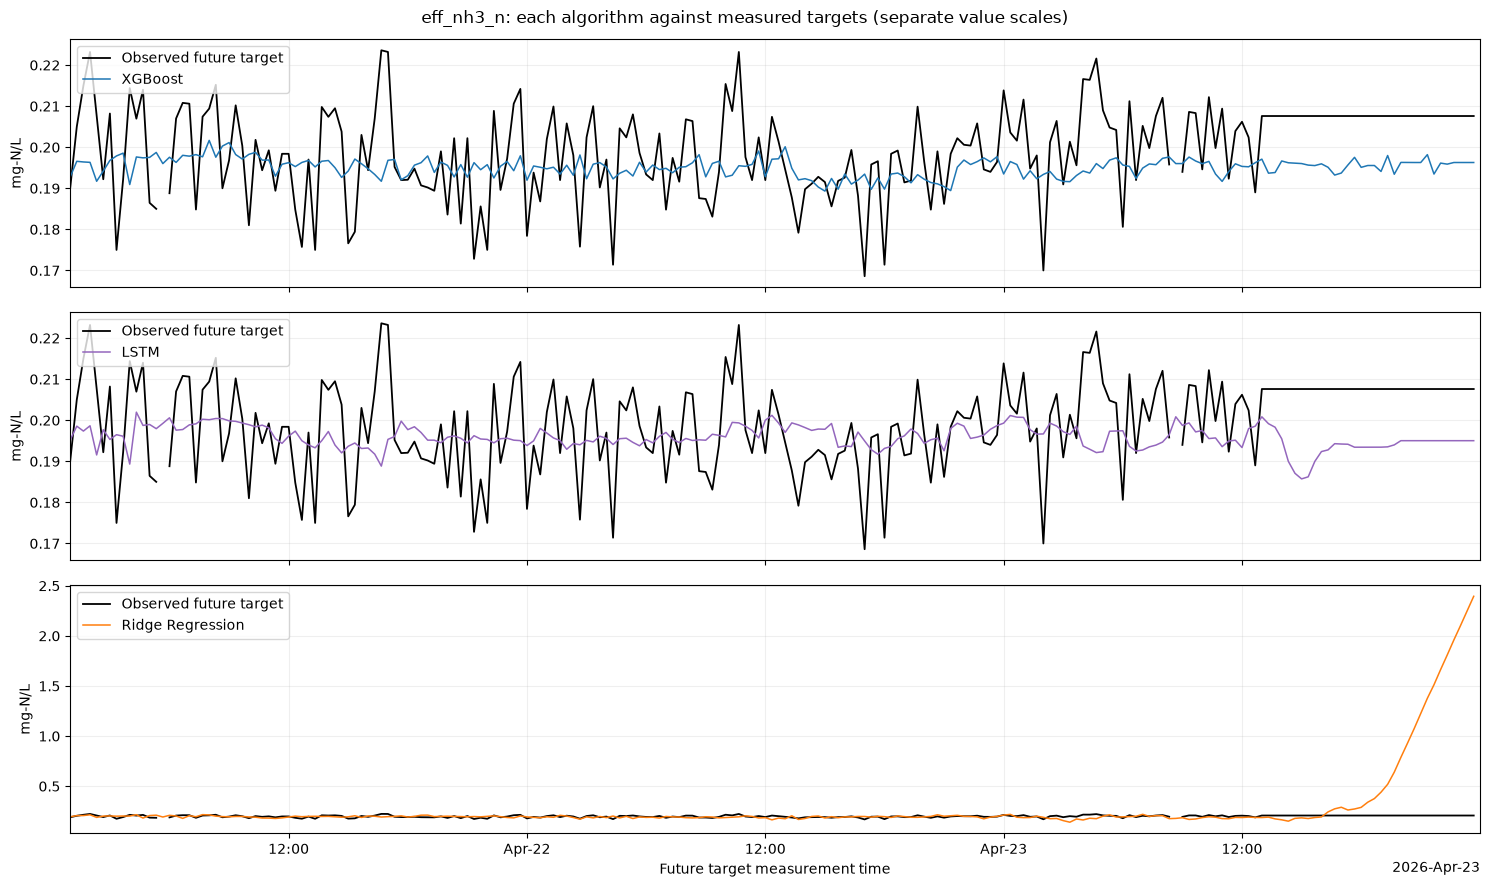

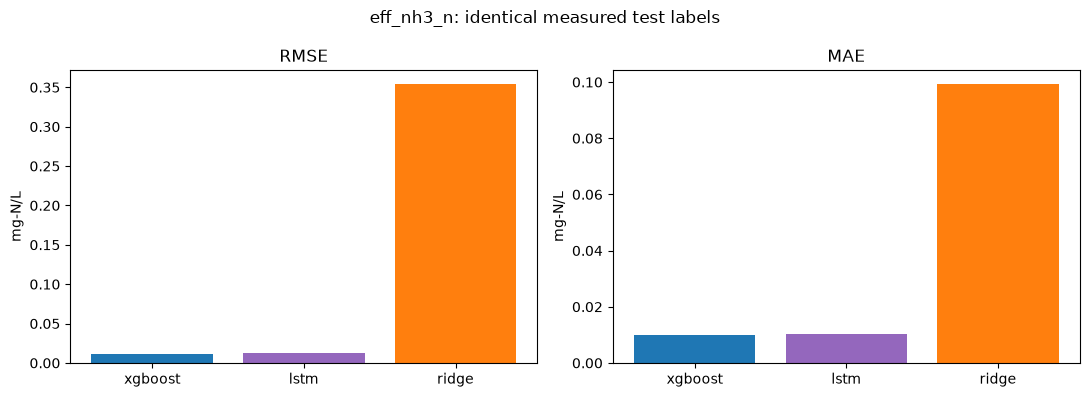

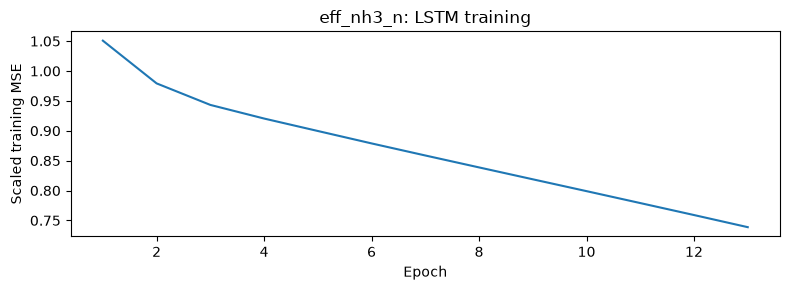

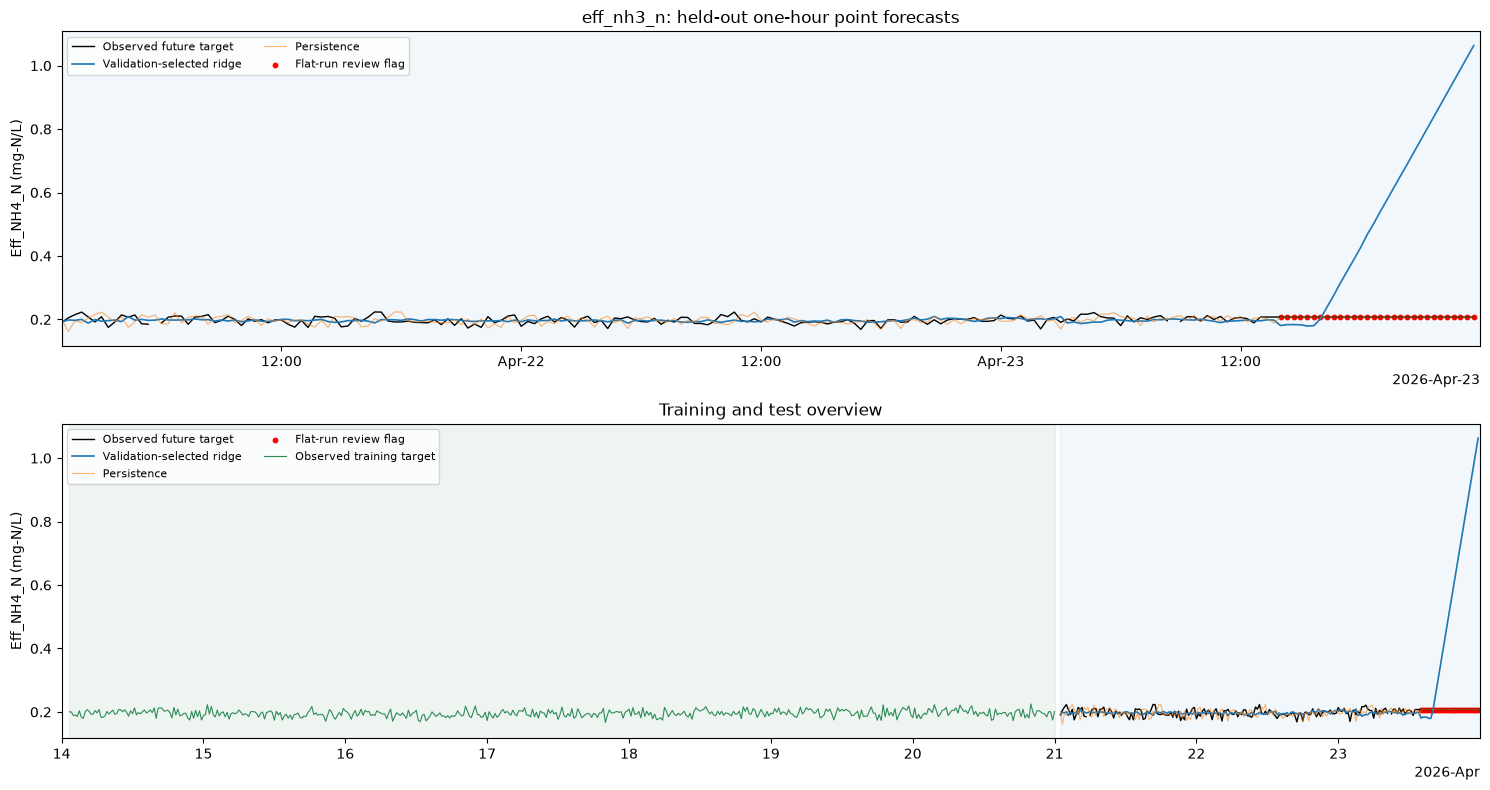

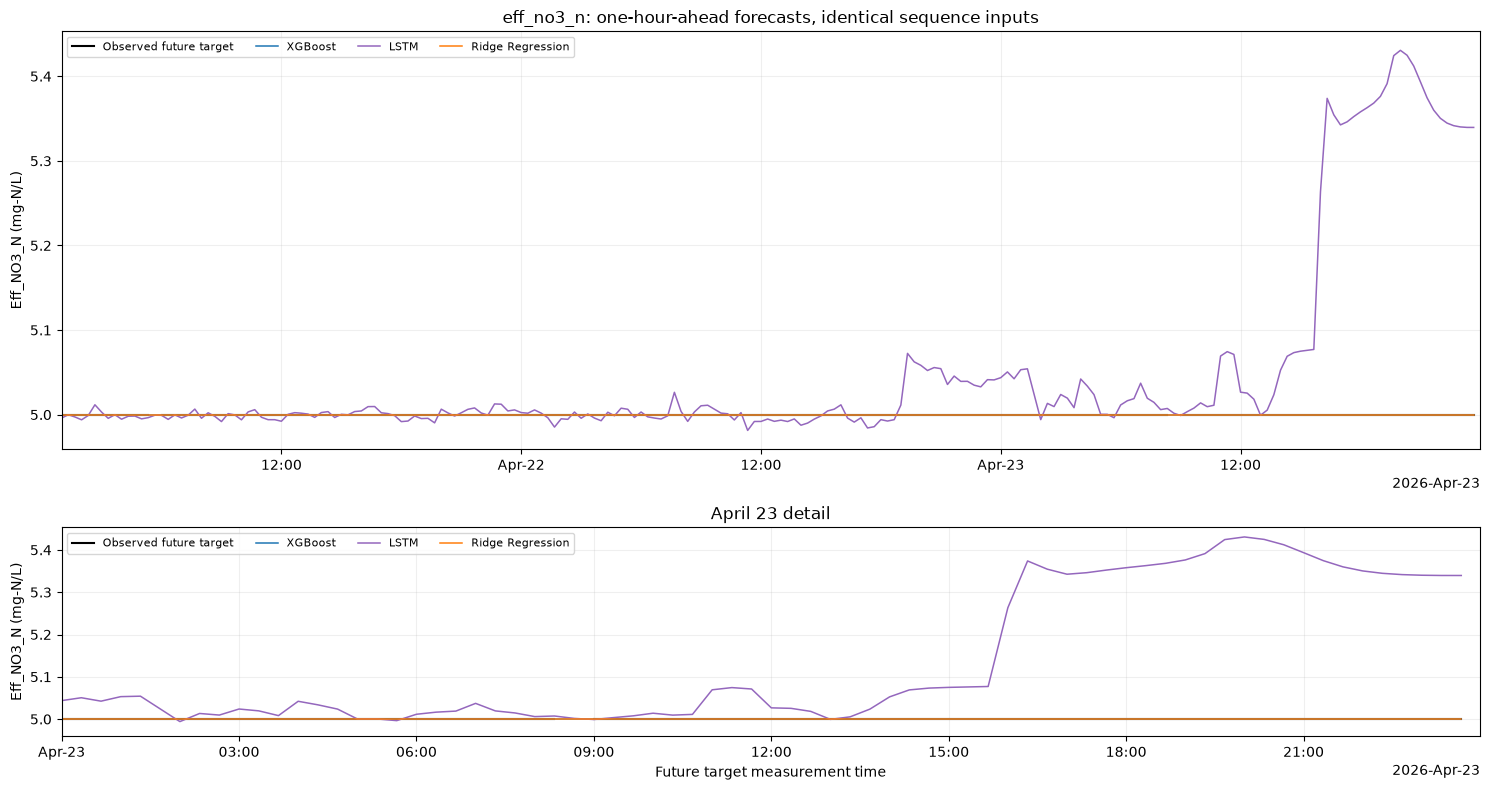

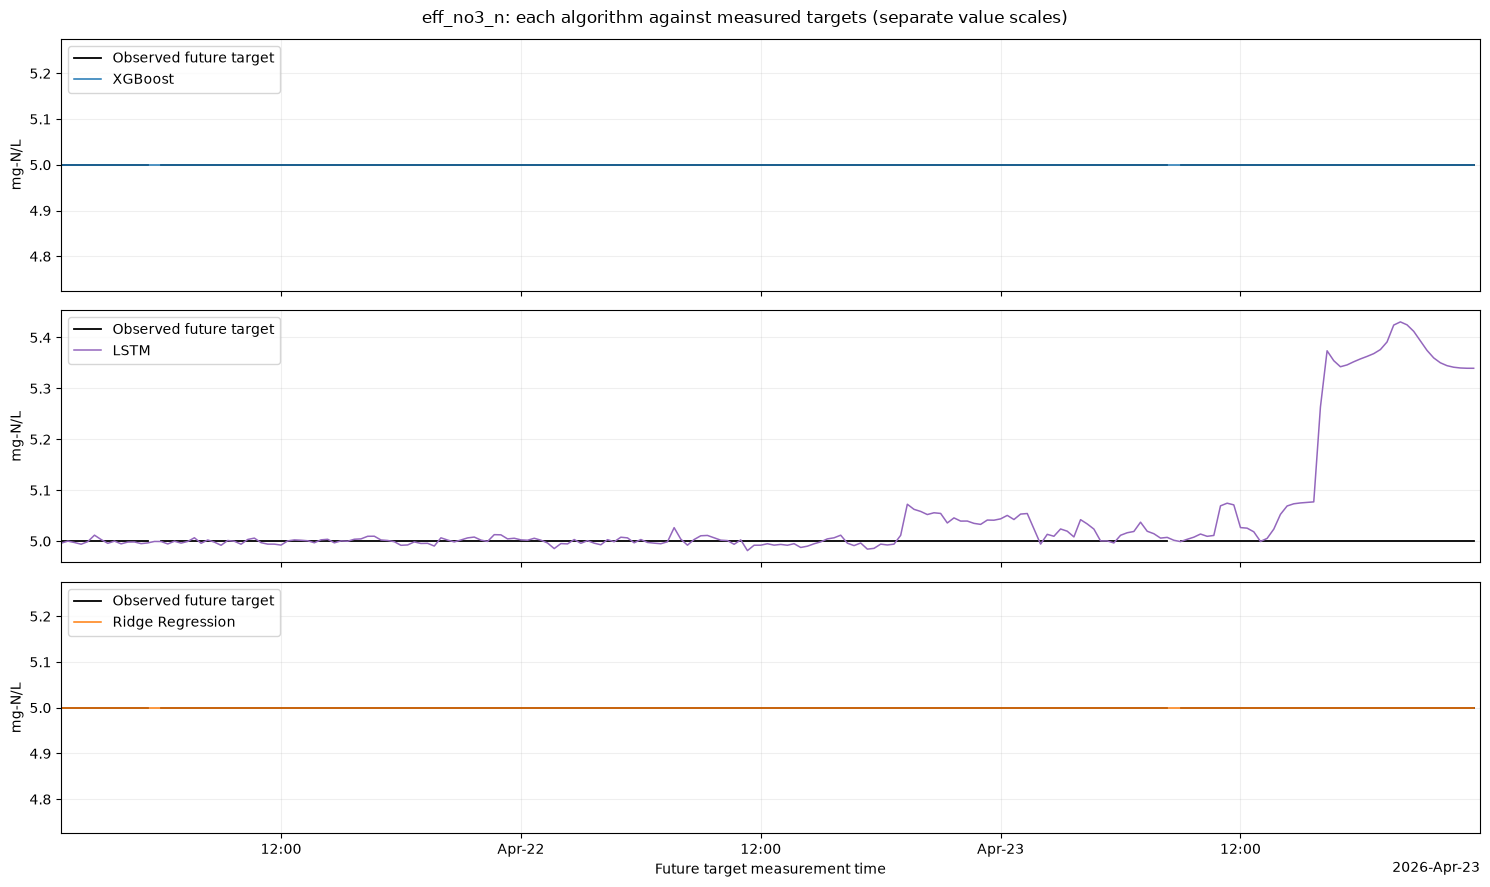

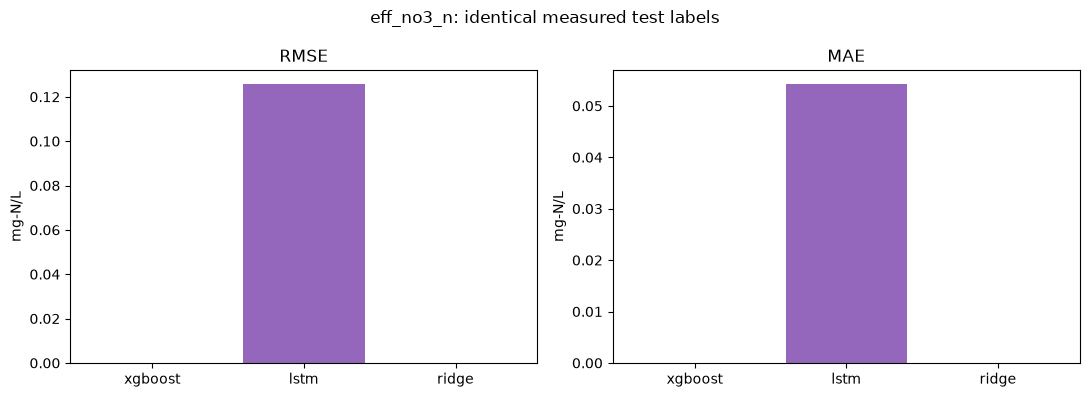

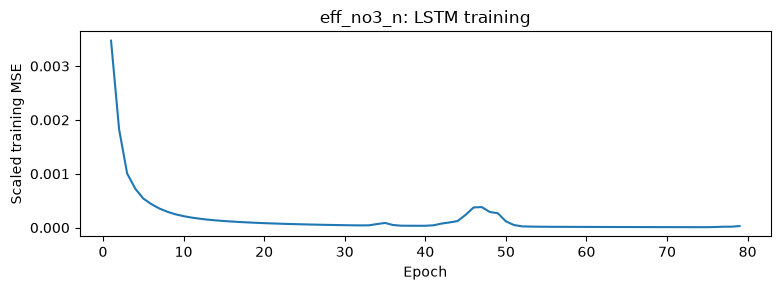

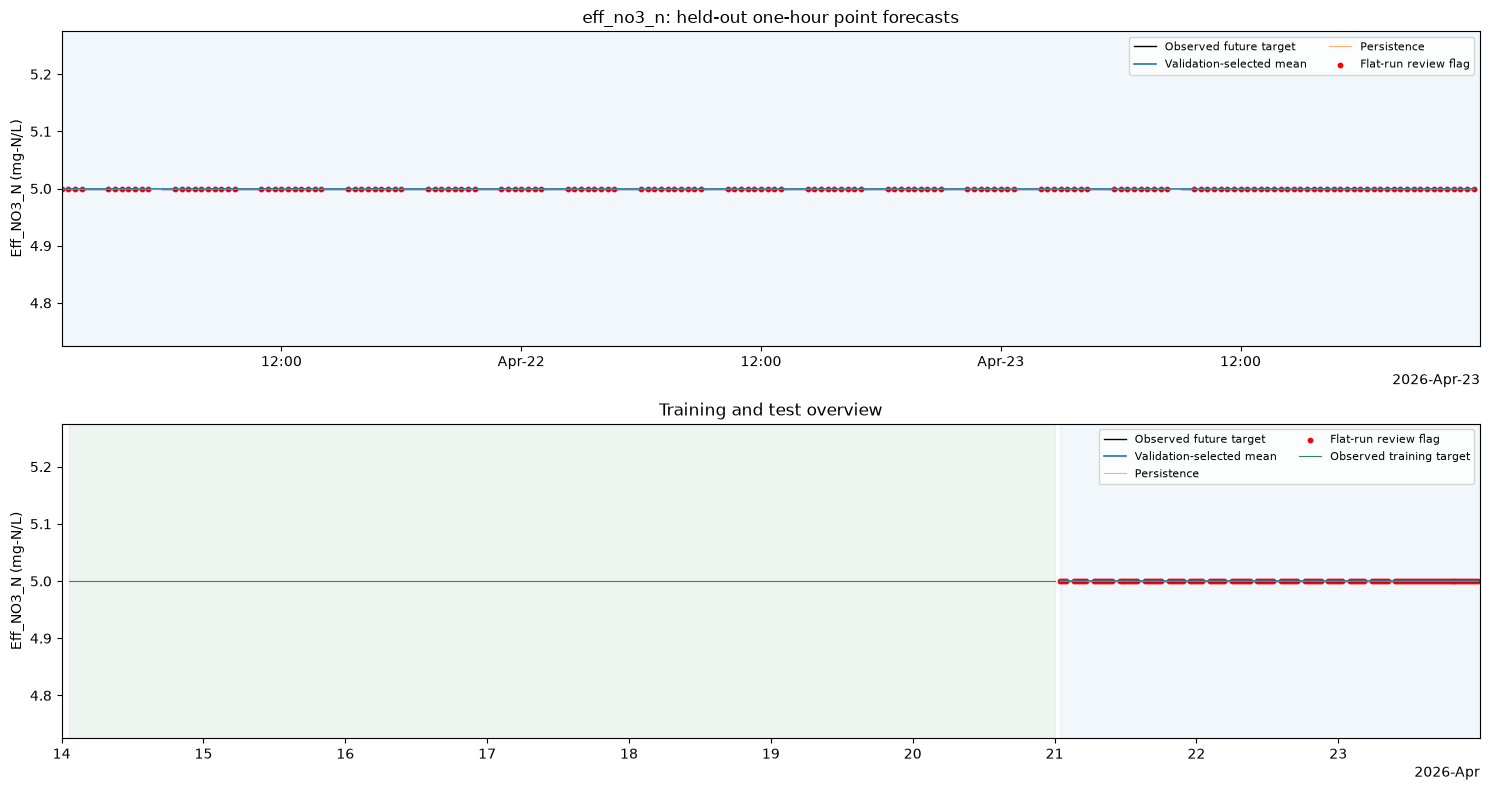

Saved comparisons, models, quality audits, feature matrices and forecasts in /home/bryan1010/projects/ao-mbr-data-pipeline/notebooks/data/preparation_strategies/effluent


In [4]:
preparation_experiments.plot_results(results, OUTPUT_DIR)
print(f"Saved comparisons, models, quality audits, feature matrices and forecasts in {OUTPUT_DIR}")
